# Stage 7 — Interpretability and Error Diagnostics

Diagnose the validated v1 XGBoost models rather than changing them. This notebook compares H+1 and H+7 SHAP importance, then evaluates H+3 residuals over every 2023 row with an observed target. Spatial error is aggregated into adequately sampled 0.1° bins; seasonal and residual diagnostics remain descriptive rather than assumptions imposed by the gate.


## 7.0 — Load data, manifest, models

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import xgboost as xgb

PROC_DIR = Path("data/processed")
MODEL_DIR = Path("models")
FIG_DIR = Path("figs")
FIG_DIR.mkdir(parents=True, exist_ok=True)

SAMPLE_PATH = PROC_DIR / "supervised_sample.parquet"
FEATURE_MANIFEST_PATH = PROC_DIR / "feature_manifest.json"
SPLIT_MANIFEST_PATH = PROC_DIR / "split_manifest.json"
MODEL_MANIFEST_PATH = PROC_DIR / "xgb_model_manifest.json"
ALL_SCORE_PATH = PROC_DIR / "xgb_scores_all_targets.csv"

for path in (
    SAMPLE_PATH,
    FEATURE_MANIFEST_PATH,
    SPLIT_MANIFEST_PATH,
    MODEL_MANIFEST_PATH,
    ALL_SCORE_PATH,
):
    assert path.exists(), f"Missing {path}"

df = pd.read_parquet(SAMPLE_PATH)
df["time"] = pd.to_datetime(df["time"])

manifest = json.loads(FEATURE_MANIFEST_PATH.read_text())
split_protocol = json.loads(SPLIT_MANIFEST_PATH.read_text())
model_manifest = json.loads(MODEL_MANIFEST_PATH.read_text())

FEATURE_COLS = manifest["feature_cols"]
HORIZONS = manifest["horizons"]

TEST_START = pd.Timestamp(split_protocol["test_start"])
TEST_END = pd.Timestamp(split_protocol["test_end"])

test = (
    df[df["time"].between(TEST_START, TEST_END)]
    .sort_values(["time", "latitude", "longitude"])
    .reset_index(drop=True)
)

xgb_all_scores = (
    pd.read_csv(ALL_SCORE_PATH)
    .set_index("horizon")
    .sort_index()
)

models = {}

for h in HORIZONS:
    model_path = MODEL_DIR / f"xgb_h{h}.json"
    assert model_path.exists(), f"Missing {model_path}"

    model = xgb.XGBRegressor()
    model.load_model(model_path)

    model_features = model.get_booster().feature_names

    if (
        model_features is not None
        and list(model_features) != list(FEATURE_COLS)
    ):
        raise RuntimeError(
            f"H+{h} model feature order does not match the manifest"
        )

    models[h] = model

print(f"Loaded models : {len(models)}")
print(f"Test rows     : {len(test):,}")
print(
    f"Test range    : {test.time.min().date()} → "
    f"{test.time.max().date()}"
)
print(f"Test months   : {sorted(test.time.dt.month.unique())}")
print(f"Features      : {len(FEATURE_COLS)}")

Loaded models : 7
Test rows     : 120,000
Test range    : 2023-01-01 → 2023-12-30
Test months   : [np.int32(1), np.int32(2), np.int32(3), np.int32(4), np.int32(5), np.int32(6), np.int32(7), np.int32(8), np.int32(9), np.int32(10), np.int32(11), np.int32(12)]
Features      : 15


## 7.1 — SHAP feature importance at H+1 and H+7

Use tree-aware SHAP on a reproducible sample of up to 5,000 test rows per horizon. H+1 reveals the drivers of short-range forecasts; H+7 shows which signals remain useful as autoregressive information weakens. Read correlated predictors as families rather than over-interpreting small rank differences.


In [2]:
import shap

# Sample every month explicitly so SHAP represents the complete test year.
SHAP_PER_MONTH = 400

shap_parts = []

for month, group in test.groupby(test["time"].dt.month):
    shap_parts.append(
        group.sample(
            n=min(SHAP_PER_MONTH, len(group)),
            random_state=100 + int(month),
        )
    )

sample_for_shap = (
    pd.concat(shap_parts, ignore_index=True)
    [FEATURE_COLS]
)

shap_values = {}

for h in [1, 7]:
    explainer = shap.TreeExplainer(models[h])
    values = explainer.shap_values(sample_for_shap)

    if values.shape != sample_for_shap.shape:
        raise RuntimeError(
            f"Unexpected H+{h} SHAP shape: {values.shape}"
        )

    shap_values[h] = values

    print(
        f"H+{h}: SHAP computed for "
        f"{values.shape[0]:,} rows × {values.shape[1]} features"
    )

H+1: SHAP computed for 4,800 rows × 15 features
H+7: SHAP computed for 4,800 rows × 15 features


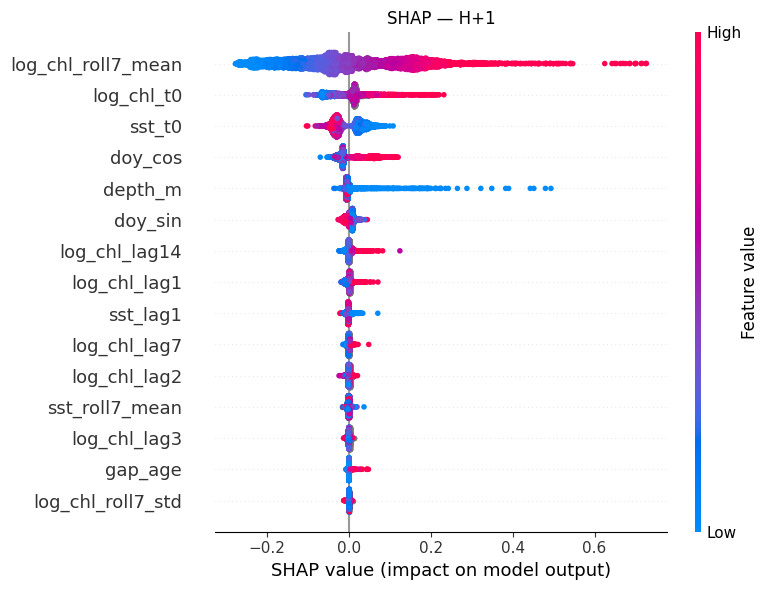

In [3]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))
shap.summary_plot(shap_values[1], sample_for_shap, show=False, plot_size=None)
plt.title("SHAP — H+1")
plt.tight_layout()
plt.savefig(FIG_DIR / "07_shap_h1.png", dpi=150, bbox_inches="tight")
plt.show()

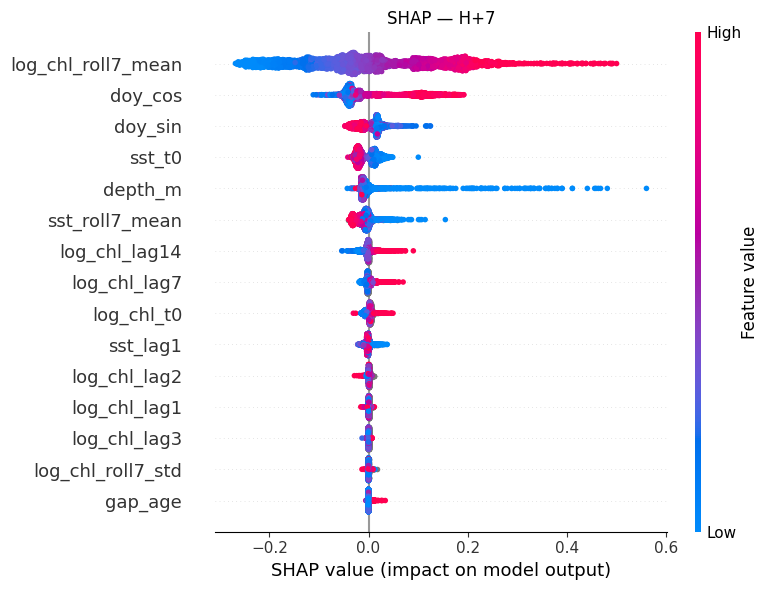

In [4]:
plt.figure(figsize=(8, 6))
shap.summary_plot(shap_values[7], sample_for_shap, show=False, plot_size=None)
plt.title("SHAP — H+7")
plt.tight_layout()
plt.savefig(FIG_DIR / "07_shap_h7.png", dpi=150, bbox_inches="tight")
plt.show()

### Mean absolute SHAP — direct comparison

The summary plots are dense. A bar chart of mean |SHAP| per feature, side-by-side for H+1 and H+7, makes the *change in importance ranking* with horizon legible at a glance.

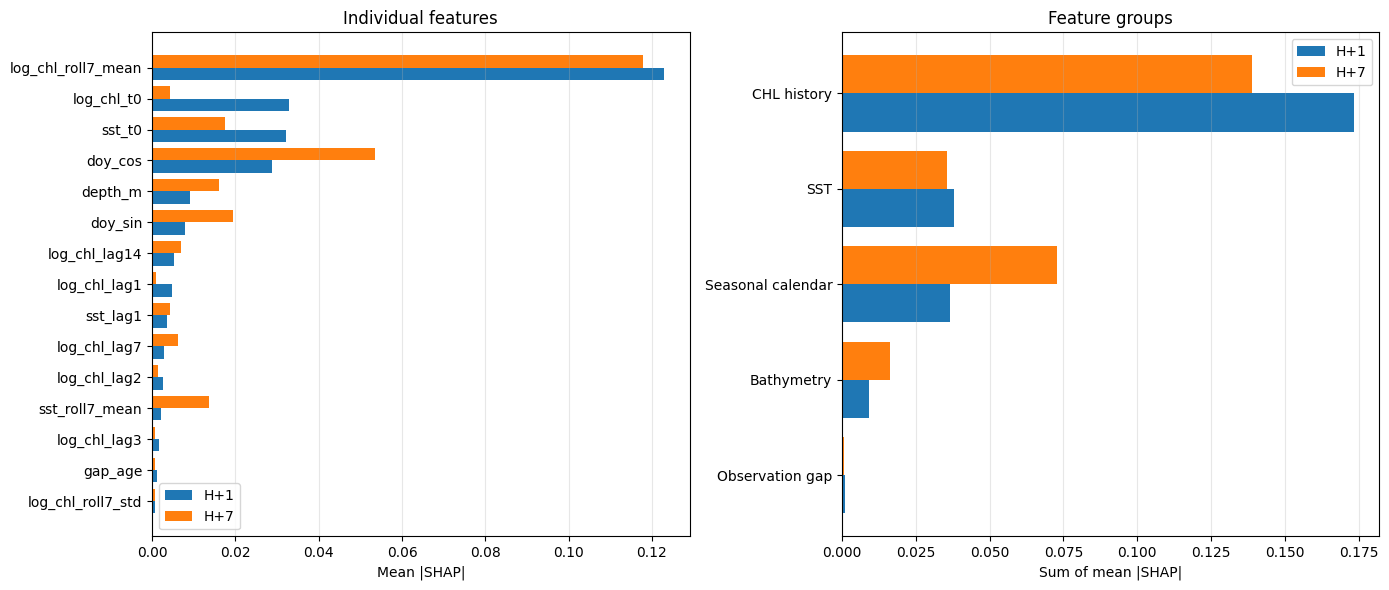

Top five individual features:

H+1:
  log_chl_roll7_mean        0.1229
  log_chl_t0                0.0329
  sst_t0                    0.0321
  doy_cos                   0.0288
  depth_m                   0.0091

H+7:
  log_chl_roll7_mean        0.1178
  doy_cos                   0.0535
  doy_sin                   0.0193
  sst_t0                    0.0176
  depth_m                   0.0162

Grouped importance:
            group    H+1    H+7
      CHL history 0.1734 0.1390
              SST 0.0379 0.0355
Seasonal calendar 0.0367 0.0728
       Bathymetry 0.0091 0.0162
  Observation gap 0.0011 0.0006


In [5]:
shap_summary = pd.DataFrame({
    "feature": FEATURE_COLS,
    "H+1": np.abs(shap_values[1]).mean(axis=0),
    "H+7": np.abs(shap_values[7]).mean(axis=0),
})

SHAP_GROUPS = {
    "CHL history": [
        col for col in FEATURE_COLS
        if col.startswith("log_chl_")
    ],
    "Observation gap": ["gap_age"],
    "SST": [
        col for col in FEATURE_COLS
        if col.startswith("sst_")
    ],
    "Bathymetry": ["depth_m"],
    "Seasonal calendar": ["doy_sin", "doy_cos"],
}

group_rows = []

for group_name, columns in SHAP_GROUPS.items():
    existing = [
        column for column in columns
        if column in FEATURE_COLS
    ]

    group_rows.append({
        "group": group_name,
        "H+1": shap_summary.loc[
            shap_summary["feature"].isin(existing),
            "H+1",
        ].sum(),
        "H+7": shap_summary.loc[
            shap_summary["feature"].isin(existing),
            "H+7",
        ].sum(),
    })

group_summary = pd.DataFrame(group_rows)

individual_plot = shap_summary.sort_values(
    "H+1",
    ascending=True,
)
group_plot = group_summary.sort_values(
    "H+1",
    ascending=True,
)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

y_individual = np.arange(len(individual_plot))

axes[0].barh(
    y_individual - 0.2,
    individual_plot["H+1"],
    height=0.4,
    label="H+1",
)
axes[0].barh(
    y_individual + 0.2,
    individual_plot["H+7"],
    height=0.4,
    label="H+7",
)
axes[0].set_yticks(y_individual)
axes[0].set_yticklabels(individual_plot["feature"])
axes[0].set_xlabel("Mean |SHAP|")
axes[0].set_title("Individual features")
axes[0].legend()
axes[0].grid(alpha=0.3, axis="x")

y_group = np.arange(len(group_plot))

axes[1].barh(
    y_group - 0.2,
    group_plot["H+1"],
    height=0.4,
    label="H+1",
)
axes[1].barh(
    y_group + 0.2,
    group_plot["H+7"],
    height=0.4,
    label="H+7",
)
axes[1].set_yticks(y_group)
axes[1].set_yticklabels(group_plot["group"])
axes[1].set_xlabel("Sum of mean |SHAP|")
axes[1].set_title("Feature groups")
axes[1].legend()
axes[1].grid(alpha=0.3, axis="x")

plt.tight_layout()
plt.savefig(
    FIG_DIR / "07_shap_bar_h1_h7.png",
    dpi=150,
)
plt.show()

print("Top five individual features:")

for h in [1, 7]:
    top = (
        shap_summary
        .sort_values(f"H+{h}", ascending=False)
        .head(5)
    )

    print(f"\nH+{h}:")
    for _, row in top.iterrows():
        print(
            f"  {row['feature']:25s} "
            f"{row[f'H+{h}']:.4f}"
        )

print("\nGrouped importance:")
print(
    group_summary
    .sort_values("H+1", ascending=False)
    .round(4)
    .to_string(index=False)
)

calendar_h1 = float(
    group_summary.loc[
        group_summary["group"] == "Seasonal calendar",
        "H+1",
    ].iloc[0]
)
total_h1 = float(group_summary["H+1"].sum())
calendar_share_h1 = calendar_h1 / total_h1

## 7.2 — H+3 residuals on all observed targets

Use H+3 as the reference horizon and score every 2023 row with an observed H+3 target, including rows where issue-time CHL is missing. The expected row count is read from Notebook 6's all-observed-target artifact, so these diagnostics are not silently restricted to the persistence comparison mask.


In [6]:
REF_H = 3
target_col = f"target_h{REF_H}"

target_mask = test[target_col].notna()

X_diag = test.loc[target_mask, FEATURE_COLS]
y_diag = test.loc[target_mask, target_col].to_numpy()
pred_diag = models[REF_H].predict(X_diag)

diag = test.loc[
    target_mask,
    ["time", "latitude", "longitude"],
].copy()

diag["y"] = y_diag
diag["pred"] = pred_diag
diag["residual"] = diag["pred"] - diag["y"]
diag["abs_residual"] = np.abs(diag["residual"])
diag["month"] = diag["time"].dt.month

expected_n = int(xgb_all_scores.loc[REF_H, "n"])

if len(diag) != expected_n:
    raise RuntimeError(
        f"H+{REF_H} diagnostic N={len(diag):,}, "
        f"but Notebook 6 recorded {expected_n:,}"
    )

print(f"Reference horizon : H+{REF_H}")
print(f"Test rows scored  : {len(diag):,}")
print(f"MAE               : {diag.abs_residual.mean():.4f}")
print(
    f"RMSE              : "
    f"{np.sqrt(np.mean(diag.residual ** 2)):.4f}"
)
print(
    f"Bias              : {diag.residual.mean():+.4f} "
    "(positive = overprediction)"
)

Reference horizon : H+3
Test rows scored  : 71,709
MAE               : 0.0858
RMSE              : 0.1261
Bias              : -0.0062 (positive = overprediction)


## 7.3 — Spatial-bin error map

Aggregate H+3 residuals into 0.1° latitude/longitude bins and retain bins with at least 30 observations. Plot both mean absolute error and signed bias. This stabilizes the map relative to per-pixel estimates from the sparse supervised sample.


Spatial bins with at least 30 observations: 602 / 619


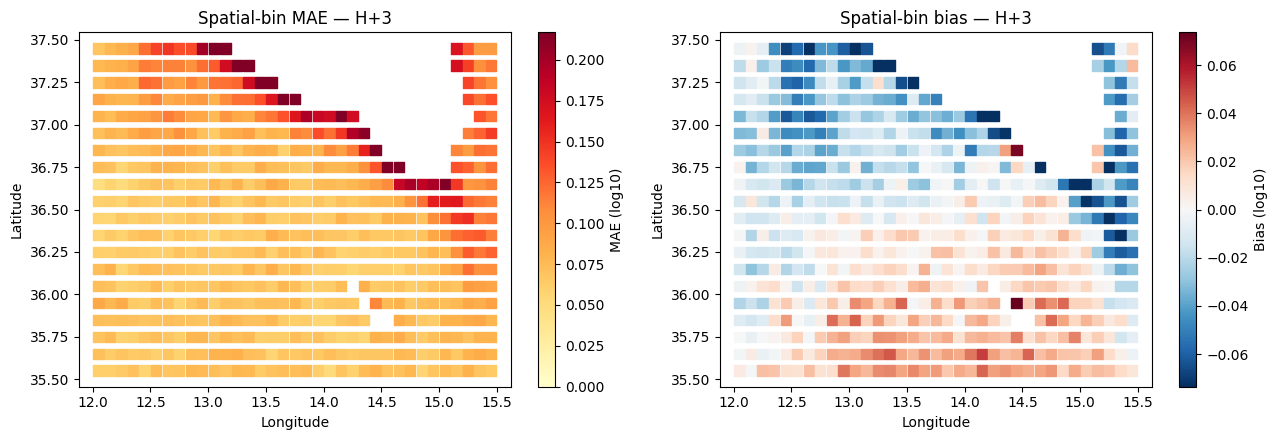

In [7]:
SPATIAL_BIN_DEG = 0.1
MIN_BIN_N = 30

diag["latitude_bin"] = (
    np.floor(diag["latitude"] / SPATIAL_BIN_DEG)
    * SPATIAL_BIN_DEG
    + SPATIAL_BIN_DEG / 2
)
diag["longitude_bin"] = (
    np.floor(diag["longitude"] / SPATIAL_BIN_DEG)
    * SPATIAL_BIN_DEG
    + SPATIAL_BIN_DEG / 2
)

spatial_error = (
    diag.groupby(
        ["latitude_bin", "longitude_bin"],
        as_index=False,
    )
    .agg(
        mae=("abs_residual", "mean"),
        bias=("residual", "mean"),
        n=("abs_residual", "size"),
    )
)

spatial_valid = spatial_error[
    spatial_error["n"] >= MIN_BIN_N
].copy()

print(
    f"Spatial bins with at least {MIN_BIN_N} observations: "
    f"{len(spatial_valid):,} / {len(spatial_error):,}"
)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

mae_limit = spatial_valid["mae"].quantile(0.98)

im0 = axes[0].scatter(
    spatial_valid["longitude_bin"],
    spatial_valid["latitude_bin"],
    c=spatial_valid["mae"],
    cmap="YlOrRd",
    marker="s",
    s=55,
    vmin=0,
    vmax=mae_limit,
)
axes[0].set_title(f"Spatial-bin MAE — H+{REF_H}")
axes[0].set_xlabel("Longitude")
axes[0].set_ylabel("Latitude")
plt.colorbar(im0, ax=axes[0], label="MAE (log10)")

bias_limit = max(
    0.01,
    float(
        np.nanmax(
            np.abs(
                spatial_valid["bias"]
                .quantile([0.02, 0.98])
                .to_numpy()
            )
        )
    ),
)

im1 = axes[1].scatter(
    spatial_valid["longitude_bin"],
    spatial_valid["latitude_bin"],
    c=spatial_valid["bias"],
    cmap="RdBu_r",
    marker="s",
    s=55,
    vmin=-bias_limit,
    vmax=bias_limit,
)
axes[1].set_title(f"Spatial-bin bias — H+{REF_H}")
axes[1].set_xlabel("Longitude")
axes[1].set_ylabel("Latitude")
plt.colorbar(im1, ax=axes[1], label="Bias (log10)")

plt.tight_layout()
plt.savefig(
    FIG_DIR / "07_error_map_h3.png",
    dpi=150,
)
plt.show()

## 7.4 — Error by month

Compare the distribution, mean absolute error, and bias across all 12 months. Winter and summer summaries are reported, but their direction is an empirical finding—not a gate requirement. Interpret any seasonal pattern alongside the measured CHL coverage from Notebook 2.


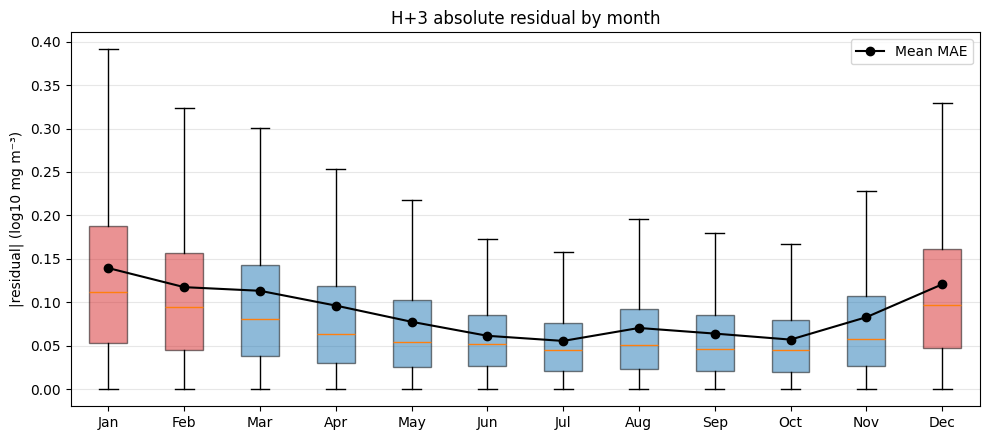

          n     mae    bias
month                      
1      5389  0.1394 -0.0362
2      5343  0.1175 -0.0420
3      6737  0.1133 -0.0365
4      6709  0.0963 -0.0034
5      3984  0.0777 -0.0255
6      5993  0.0615 -0.0067
7      7380  0.0556  0.0079
8      7877  0.0705  0.0132
9      6431  0.0641  0.0212
10     6385  0.0572  0.0092
11     5395  0.0829 -0.0223
12     4086  0.1207  0.0371

Winter DJF MAE       : 0.1264
Summer JJA MAE       : 0.0628
Winter/summer ratio  : 2.01×


In [8]:
MONTH_LABELS = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec",
]

by_month = [
    diag.loc[
        diag["month"] == month,
        "abs_residual",
    ].to_numpy()
    for month in range(1, 13)
]

monthly_summary = (
    diag.groupby("month")
    .agg(
        n=("abs_residual", "size"),
        mae=("abs_residual", "mean"),
        bias=("residual", "mean"),
    )
    .reindex(range(1, 13))
)

fig, ax = plt.subplots(figsize=(10, 4.5))

boxplot = ax.boxplot(
    by_month,
    tick_labels=MONTH_LABELS,
    showfliers=False,
    patch_artist=True,
)

for patch, month in zip(boxplot["boxes"], range(1, 13)):
    patch.set_facecolor(
        "#d62728"
        if month in (12, 1, 2)
        else "#1f77b4"
    )
    patch.set_alpha(0.5)

ax.plot(
    range(1, 13),
    monthly_summary["mae"],
    marker="o",
    color="black",
    label="Mean MAE",
)

ax.set_ylabel("|residual| (log10 mg m⁻³)")
ax.set_title(
    f"H+{REF_H} absolute residual by month"
)
ax.legend()
ax.grid(alpha=0.3, axis="y")

plt.tight_layout()
plt.savefig(
    FIG_DIR / "07_error_by_month.png",
    dpi=150,
)
plt.show()

winter_mask = diag["month"].isin([12, 1, 2])
summer_mask = diag["month"].isin([6, 7, 8])

winter_mae = float(
    diag.loc[winter_mask, "abs_residual"].mean()
)
summer_mae = float(
    diag.loc[summer_mask, "abs_residual"].mean()
)
winter_summer_ratio = winter_mae / summer_mae

print(monthly_summary.round(4).to_string())
print(f"\nWinter DJF MAE       : {winter_mae:.4f}")
print(f"Summer JJA MAE       : {summer_mae:.4f}")
print(f"Winter/summer ratio  : {winter_summer_ratio:.2f}×")

## 7.5 — Residual diagnostics

Two scatter plots:
- **Pred vs actual** — points should lie close to the 1:1 line. Compression toward the mean (a "shrinkage") is normal for tree models on noisy data.
- **Residual vs predicted** — looking for *structure*: a fan shape is heteroscedasticity (OK, common); a slope means the model has a systematic bias proportional to prediction (missing feature).

We thin to 5000 random points for legibility.

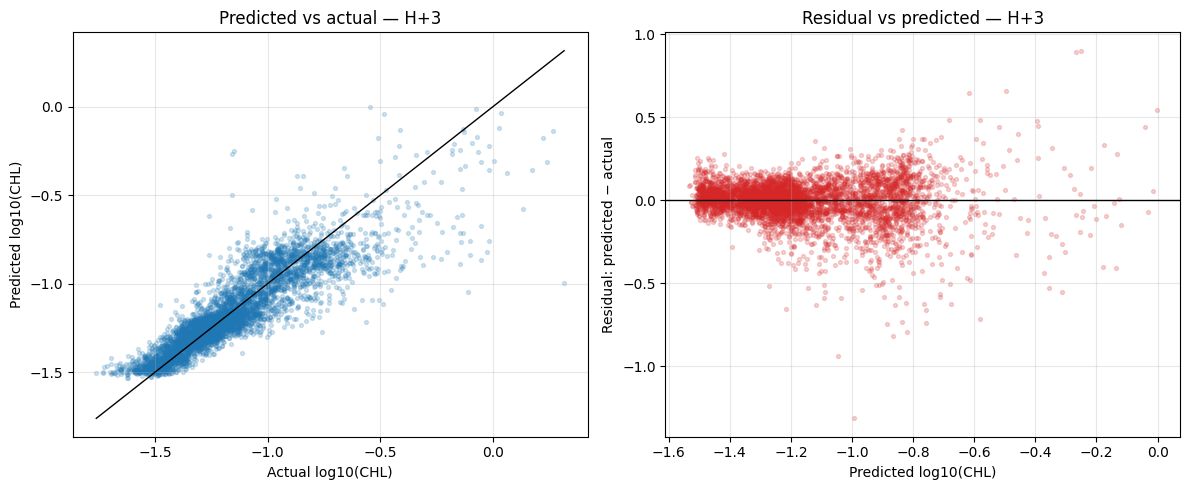

Pearson(residual, predicted), all H+3 rows: -0.127


In [9]:
plot_sample = diag.sample(
    n=min(5000, len(diag)),
    random_state=0,
)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(
    plot_sample["y"],
    plot_sample["pred"],
    alpha=0.2,
    s=8,
)
lower = min(
    plot_sample["y"].min(),
    plot_sample["pred"].min(),
)
upper = max(
    plot_sample["y"].max(),
    plot_sample["pred"].max(),
)
axes[0].plot(
    [lower, upper],
    [lower, upper],
    color="black",
    linewidth=1,
)
axes[0].set_xlabel("Actual log10(CHL)")
axes[0].set_ylabel("Predicted log10(CHL)")
axes[0].set_title(f"Predicted vs actual — H+{REF_H}")
axes[0].grid(alpha=0.3)

axes[1].scatter(
    plot_sample["pred"],
    plot_sample["residual"],
    alpha=0.2,
    s=8,
    color="#d62728",
)
axes[1].axhline(0, color="black", linewidth=1)
axes[1].set_xlabel("Predicted log10(CHL)")
axes[1].set_ylabel("Residual: predicted − actual")
axes[1].set_title(f"Residual vs predicted — H+{REF_H}")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(
    FIG_DIR / "07_residual_diagnostics_h3.png",
    dpi=150,
)
plt.show()

# Calculate this on every diagnostic row, not only the plotting sample.
corr = float(
    diag[["residual", "pred"]]
    .corr()
    .iloc[0, 1]
)

print(
    f"Pearson(residual, predicted), all H+{REF_H} rows: "
    f"{corr:+.3f}"
)

---
## Validation Gate 7

The automated gate checks complete monthly test coverage, agreement with Notebook 6's all-target H+3 count, SHAP dimensions, a physically plausible leading H+1 CHL/SST driver, limited dominance by calendar terms, at least 100 adequately sampled spatial bins, finite winter/summer diagnostics, and moderate residual–prediction correlation. It reports the seasonal direction without requiring winter error to exceed summer error.


In [12]:
results = {}

top_h1 = (
    shap_summary
    .sort_values("H+1", ascending=False)
    .iloc[0]["feature"]
)

plausible_drivers = {
    "log_chl_t0",
    "log_chl_lag1",
    "log_chl_lag2",
    "log_chl_lag3",
    "log_chl_lag7",
    "log_chl_lag14",
    "log_chl_roll7_mean",
    "log_chl_roll7_std",
    "sst_t0",
    "sst_lag1",
    "sst_roll7_mean",
}

results["test set contains all 12 months"] = (
    set(test["time"].dt.month.unique())
    == set(range(1, 13))
)

results["H+3 diagnostic N matches Notebook 6"] = (
    len(diag) == int(xgb_all_scores.loc[REF_H, "n"])
)

results["SHAP dimensions match the feature manifest"] = all(
    shap_values[h].shape[1] == len(FEATURE_COLS)
    for h in [1, 7]
)

results["H+1 top feature is a CHL/SST driver"] = (
    top_h1 in plausible_drivers
)

results["calendar contributes under 50% of H+1 SHAP"] = (
    calendar_share_h1 < 0.50
)

results["at least 100 spatial bins are adequately sampled"] = (
    len(spatial_valid) >= 100
)

results["winter and summer diagnostics are finite"] = (
    np.isfinite(winter_mae)
    and np.isfinite(summer_mae)
)

results["residual-prediction correlation is moderate"] = (
    abs(corr) < 0.30
)

for name, ok in results.items():
    print(f"{'PASS' if ok else 'FAIL'}  {name}")

print(f"\nTop H+1 feature          : {top_h1}")
print(f"H+1 calendar SHAP share : {calendar_share_h1:.1%}")
print(f"Spatial bins retained    : {len(spatial_valid):,}")
print(f"Winter/summer MAE ratio  : {winter_summer_ratio:.2f}×")
print(f"Residual/pred correlation: {corr:+.3f}")

if winter_summer_ratio > 1:
    print("Seasonal finding: winter error exceeds summer error.")
else:
    print("Seasonal finding: winter error does not exceed summer error.")

failed = [
    name
    for name, ok in results.items()
    if not ok
]

if failed:
    raise RuntimeError(
        "Validation Gate 7 failed:\n- "
        + "\n- ".join(failed)
    )

interpretability_summary = {
    "test_start": str(test.time.min()),
    "test_end": str(test.time.max()),
    "reference_horizon": REF_H,
    "diagnostic_rows": len(diag),
    "h3_mae": float(diag["abs_residual"].mean()),
    "h3_bias": float(diag["residual"].mean()),
    "residual_prediction_correlation": corr,
    "winter_mae": winter_mae,
    "summer_mae": summer_mae,
    "winter_summer_ratio": winter_summer_ratio,
    "top_h1_feature": top_h1,
    "calendar_h1_shap_share": calendar_share_h1,
    "adequate_spatial_bins": len(spatial_valid),
}

(PROC_DIR / "interpretability_summary.json").write_text(
    json.dumps(interpretability_summary, indent=2)
)

print("\nGate 7 PASSED.")
print(
    "Saved → "
    f"{PROC_DIR / 'interpretability_summary.json'}"
)

PASS  test set contains all 12 months
PASS  H+3 diagnostic N matches Notebook 6
PASS  SHAP dimensions match the feature manifest
PASS  H+1 top feature is a CHL/SST driver
PASS  calendar contributes under 50% of H+1 SHAP
PASS  at least 100 spatial bins are adequately sampled
PASS  winter and summer diagnostics are finite
PASS  residual-prediction correlation is moderate

Top H+1 feature          : log_chl_roll7_mean
H+1 calendar SHAP share : 14.2%
Spatial bins retained    : 602
Winter/summer MAE ratio  : 2.01×
Residual/pred correlation: -0.127
Seasonal finding: winter error exceeds summer error.

Gate 7 PASSED.
Saved → data\processed\interpretability_summary.json


---
## What to carry into Stage 8

Use the SHAP, spatial-bin, monthly, and residual diagnostics to form hypotheses about missing predictor families; do not select variables from a visual pattern alone. Notebook 8a acquires the candidate physical/optical stack, and Notebook 8b applies grouped permutation plus retrained ablation before retaining new groups.

## Next: `08a-Download-Covariates.ipynb`


---
## 7.6 — Interactive actual/predicted/error viewer

Step through target dates and horizons with three maps: observed `log10(CHL)`, XGBoost prediction, and residual (`prediction − observation`). The number and spatial distribution of sampled points vary by date and horizon. For readability, the viewer linearly interpolates available scattered points onto the CHL grid and masks locations outside their convex hull.

The interpolation is visualization-only. Models and metrics use the original sampled rows, so values read from the raster must not be treated as evaluated predictions.

This optional cell requires `ipywidgets` and SciPy.


In [13]:
import xarray as xr

# Predict every horizon on the test set and stash (time, lat, lon, y, pred, residual).
diag_by_h = {}
for h in HORIZONS:
    tgt = f"target_h{h}"
    m = test[tgt].notna()
    Xh = test.loc[m, FEATURE_COLS]
    yh = test.loc[m, tgt].values
    predh = models[h].predict(Xh)
    d = test.loc[m, ["time", "latitude", "longitude"]].copy()
    d["y"] = yh
    d["pred"] = predh
    d["residual"] = predh - yh
    diag_by_h[h] = d

# Target grid for interpolation = the CHL cube's native grid.
chl_grid = xr.open_dataset(Path("data/raw/chl_malta_2021_2023.nc")).CHL
grid_lon = chl_grid.longitude.values
grid_lat = chl_grid.latitude.values
LON, LAT = np.meshgrid(grid_lon, grid_lat)

# Sorted list of unique test dates (any horizon's diag has the same date set, near enough).
test_dates = np.sort(diag_by_h[3].time.unique())
print(f"Days available in test split : {len(test_dates)}")
print(f"Range                        : {pd.Timestamp(test_dates[0]).date()} → {pd.Timestamp(test_dates[-1]).date()}")
print(f"Grid for interpolation       : {len(grid_lat)} × {len(grid_lon)}  ({len(grid_lat)*len(grid_lon):,} cells)")

Days available in test split : 340
Range                        : 2023-01-01 → 2023-12-28
Grid for interpolation       : 198 × 272  (53,856 cells)


In [14]:
from scipy.interpolate import griddata
import ipywidgets as widgets
from IPython.display import display

# Colour limits — fixed across days so frames are comparable.
CHL_VMIN, CHL_VMAX = -2.0, 0.5      # log10 mg/m^3
RES_LIM = 0.5                        # ± log10 units

def interp_to_grid(df_day, value_col):
    """Linear-interpolate scattered (lon, lat, value) onto the CHL grid.
    Points outside the convex hull of the scatter return NaN (no extrapolation)."""
    pts = df_day[["longitude", "latitude"]].values
    vals = df_day[value_col].values
    if len(pts) < 4:
        return np.full(LON.shape, np.nan)
    return griddata(pts, vals, (LON, LAT), method="linear")

def render(date_idx, horizon):
    d = pd.Timestamp(test_dates[date_idx])
    day = diag_by_h[horizon][diag_by_h[horizon].time == d]
    if len(day) == 0:
        print(f"No test data for {d.date()} at H+{horizon}")
        return

    actual_g = interp_to_grid(day, "y")
    pred_g   = interp_to_grid(day, "pred")
    resid_g  = interp_to_grid(day, "residual")

    fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

    im0 = axes[0].pcolormesh(grid_lon, grid_lat, actual_g, cmap="viridis",
                              vmin=CHL_VMIN, vmax=CHL_VMAX, shading="auto")
    axes[0].scatter(day.longitude, day.latitude, c="white", s=2, alpha=0.4)
    axes[0].set_title(f"Actual log10(CHL) — {d.date()} + {horizon}d")
    axes[0].set_xlabel("Longitude"); axes[0].set_ylabel("Latitude")
    plt.colorbar(im0, ax=axes[0], label="log10 mg m⁻³")

    im1 = axes[1].pcolormesh(grid_lon, grid_lat, pred_g, cmap="viridis",
                              vmin=CHL_VMIN, vmax=CHL_VMAX, shading="auto")
    axes[1].set_title(f"Predicted — H+{horizon}  (n={len(day)})")
    axes[1].set_xlabel("Longitude")
    plt.colorbar(im1, ax=axes[1], label="log10 mg m⁻³")

    im2 = axes[2].pcolormesh(grid_lon, grid_lat, resid_g, cmap="RdBu_r",
                              vmin=-RES_LIM, vmax=RES_LIM, shading="auto")
    axes[2].set_title(f"Residual (pred − actual)  mean={np.nanmean(np.abs(resid_g)):.3f}")
    axes[2].set_xlabel("Longitude")
    plt.colorbar(im2, ax=axes[2], label="log10")

    plt.tight_layout()
    plt.show()

# Build the widget controls
slider = widgets.IntSlider(
    value=0, min=0, max=len(test_dates) - 1, step=1,
    description="Day idx", continuous_update=False, layout=widgets.Layout(width="500px"),
)
play = widgets.Play(
    value=0, min=0, max=len(test_dates) - 1, step=1, interval=600,
    description="Play",
)
horizon_dd = widgets.Dropdown(
    options=[(f"H+{h}", h) for h in HORIZONS], value=3, description="Horizon",
)
date_label = widgets.Label(value=str(pd.Timestamp(test_dates[0]).date()))

widgets.jslink((play, "value"), (slider, "value"))

def on_slider(change):
    date_label.value = str(pd.Timestamp(test_dates[change["new"]]).date())
slider.observe(on_slider, names="value")

ui = widgets.HBox([play, slider, horizon_dd, date_label])
out = widgets.interactive_output(render, {"date_idx": slider, "horizon": horizon_dd})

display(ui, out)

Output()